# Finetune RoBERTa + ResNet-101: Tiếp tục huấn luyện từ Epoch 30 -> 40 (Thêm 10 Epochs)

Tiếp tục huấn luyện từ checkpoint output **Epoch 30** (`last_checkpoint.pth` hoặc `best_model_weights.pth`), **KHÔNG train lại từ đầu**:
- **Khởi đầu:** Tự động phát hiện và nạp trọng số, trạng thái Optimizer & Scheduler từ Epoch 30.
- **Số epoch chạy tiếp:** 10 epochs (huấn luyện từ Epoch 31 đến Epoch 40).
- **Khôi phục trạng thái:** Khôi phục `model_state_dict`, `optimizer_state_dict`, `scheduler_state_dict`, `scaler_state_dict` và `history.json` (nếu có).
- **Đánh giá & Báo cáo:** Tự động đánh giá trên tập `Test A`, xuất file `test_A_results.json`, `test_A_per_sample.csv` và vẽ biểu đồ learning curve `training_curves.png` bao quát toàn bộ 40 epochs.

## Quản lý output/dung lượng Kaggle
- Feature cache lớn được tái sử dụng nếu đã có tại `/kaggle/temp`, không tốn thời gian trích xuất lại.
- Checkpoint `last_checkpoint.pth` được cập nhật liên tục sau mỗi epoch để chống ngắt kết nối giữa chừng.
- Model tốt nhất được lưu tại `best_model_weights.pth` trong `/kaggle/working/finetune_results`.

In [1]:


from pathlib import Path
import json

# Thay bằng đường dẫn m vừa copy
ANNOTATION_PATH = Path("/kaggle/input/datasets/lamky690/refcoco/refcoco_data/person_samples.json")

DATA_DIR = ANNOTATION_PATH.parent
IMAGE_DIR = DATA_DIR / "images"

with open(ANNOTATION_PATH, encoding="utf-8") as f:
    samples = json.load(f)

# Giữ nguyên split gốc
train_samples = [s for s in samples if s["split"] == "train"]
val_samples = [s for s in samples if s["split"] == "val"]
test_samples = [s for s in samples if s["split"] == "testA"]

In [2]:
print(len(train_samples))
print(len(val_samples))
print(len(test_samples))

60357
5498
5273


{'image_id': 572383, 'file_name': 'COCO_train2014_000000572383.jpg', 'text': 'left guy', 'bbox': [136.46, 67.05, 159.5, 262.49]}


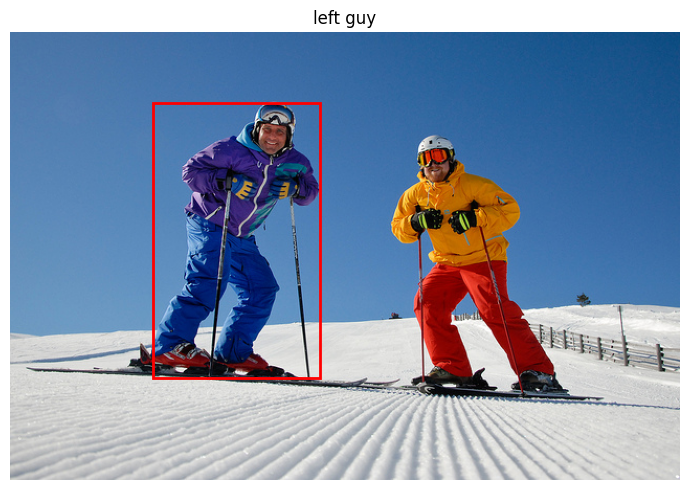

In [3]:
# Kiểm tra mẫu dữ liệu (mặc định không render ảnh để tránh notebook lưu output lớn).

from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

SHOW_SAMPLE_PREVIEW = True  # Đổi thành True khi cần xem ảnh và bounding box
sample = train_samples[min(1000, len(train_samples) - 1)]
print({
    "image_id": sample["image_id"],
    "file_name": sample["file_name"],
    "text": sample["text"],
    "bbox": sample["bbox"],
})

if SHOW_SAMPLE_PREVIEW:
    image = Image.open(IMAGE_DIR / sample["file_name"]).convert("RGB")
    x, y, w, h = sample["bbox"]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(image)
    ax.add_patch(Rectangle((x, y), w, h, edgecolor="red", facecolor="none", linewidth=2))
    ax.set_title(sample["text"])
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


In [4]:
# Mỗi ảnh chỉ tính một lần, không tính lặp theo câu mô tả
unique_images = list({
    s["image_id"]: s
    for s in train_samples
}.values())

mean_h = sum(s["height"] for s in unique_images) / len(unique_images)
mean_w = sum(s["width"] for s in unique_images) / len(unique_images)

IMAGE_SIZE = (round(mean_h), round(mean_w))  # (H, W)

print(f"Chiều cao trung bình: {mean_h:.2f}px")
print(f"Chiều rộng trung bình: {mean_w:.2f}px")
print("Kích thước resize (H, W):", IMAGE_SIZE)

Chiều cao trung bình: 487.76px
Chiều rộng trung bình: 587.82px
Kích thước resize (H, W): (488, 588)


In [5]:
import gc
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Normalize dành cho hướng dùng ResNet pretrained ImageNet
image_transform = transforms.Compose(
    [
        transforms.Resize(IMAGE_SIZE),  # (H, W), resize trực tiếp
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        ),
    ]
)


class RefCOCODataset(Dataset):

    def __init__(self, samples, image_dir, transform=None):
        self.samples = samples
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        sample = self.samples[index]

        # Đọc ảnh gốc
        with Image.open(self.image_dir / sample["file_name"]) as img:
            image = img.convert("RGB")

        W, H = image.size

        # [x, y, w, h] pixel -> [cx, cy, w, h] chuẩn hoá
        x, y, w, h = sample["bbox"]
        bbox = torch.tensor(
            [(x + w / 2) / W, (y + h / 2) / H, w / W, h / H], dtype=torch.float32
        )

        if self.transform is not None:
            image = self.transform(image)

        return {
            "image": image,
            "text": sample["text"],
            "bbox": bbox,
            "image_id": sample["image_id"],
            "ann_id": sample["ann_id"],
        }


# Gom sample thành một batch
def collate_fn(batch):
    return {
        "images": torch.stack([s["image"] for s in batch]),
        "texts": [s["text"] for s in batch],
        "boxes": torch.stack([s["bbox"] for s in batch]),
        "image_ids": [s["image_id"] for s in batch],
        "ann_ids": [s["ann_id"] for s in batch],
    }


train_dataset = RefCOCODataset(train_samples, IMAGE_DIR, image_transform)
val_dataset = RefCOCODataset(val_samples, IMAGE_DIR, image_transform)
test_dataset = RefCOCODataset(test_samples, IMAGE_DIR, image_transform)

BATCH_SIZE = 32

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": 0,  # Sửa từ 2 thành 0 để không bị văng tiến trình con trên Kaggle
    "pin_memory": torch.cuda.is_available(),
    "collate_fn": collate_fn,
}

train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

In [6]:
# Nếu thiếu transformers:
# %pip install -q transformers

import copy
import gc
import math
import json
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import resnet101, ResNet101_Weights
from torchvision.ops import (
    box_convert,
    box_iou,
    generalized_box_iou_loss,
)
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


assert torch.cuda.is_available(), "Notebook này cần bật GPU trong Kaggle."

device = torch.device("cuda:0")
N_GPUS = torch.cuda.device_count()
DEVICE_IDS = list(range(min(N_GPUS, 2)))

for i in DEVICE_IDS:
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

TEXT_MODEL = "FacebookAI/roberta-base"

# ================= CẤU HÌNH HUẤN LUYỆN TIẾP TỤC (RESUME) =================
N_FINETUNE_LAYERS = 2
FREEZE_UNTIL = 12 - N_FINETUNE_LAYERS   # 10: cache sau 10 layer đầu RoBERTa
RESNET_FINETUNE_BLOCK = "layer4"        # block cuối của ResNet101

# Chạy thêm 10 epoch từ mốc epoch 30 để đạt 40 epoch
ADDITIONAL_EPOCHS = 10                  # Số epoch huấn luyện thêm
TARGET_TOTAL_EPOCHS = 40                # Mốc tổng số epoch mục tiêu
MAX_HOURS = 9.5
LR_HEAD = 5e-5
LR_ROBERTA = 1e-5
LR_RESNET = 1e-5

BATCH_SIZE = 32
IMAGE_CACHE_BATCH_SIZE = 32
TEXT_BATCH_SIZE = 128

# Danh sách tên file checkpoint cần tìm (ưu tiên checkpoint epoch 30 / last checkpoint)
CKPT_NAMES = [
    "last_checkpoint.pth",
    "best_model_weights.pth",
    "epoch30.pth",
    "epoch_30.pth",
    "epoch-30.pth",
    "model_epoch_30.pth",
    "epoch10.pth",
    "epoch_10.pth",
]

CKPT_PATH = None

def find_checkpoint(names):
    import os
    search_dirs = ["/kaggle/input", "/kaggle/working"]
    for s_dir in search_dirs:
        if not os.path.exists(s_dir):
            continue
        for name in names:
            for root, dirs, files in os.walk(s_dir):
                dirs[:] = [d for d in dirs if d != "images"]
                if name in files:
                    return Path(root) / name
    return None

if CKPT_PATH is None:
    CKPT_PATH = find_checkpoint(CKPT_NAMES)

if CKPT_PATH is None:
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint nào trong {CKPT_NAMES} tại /kaggle/input hoặc /kaggle/working. "
        "Hãy Add Dataset chứa checkpoint output hoặc gán đường dẫn thủ công vào biến CKPT_PATH."
    )

print(">>> Đã tìm thấy Checkpoint để tiếp tục huấn luyện:", CKPT_PATH)

# Thư mục lưu kết quả
SAVE_DIR = Path("/kaggle/working/finetune_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Feature cache lưu vào /kaggle/temp
CACHE_DIR = Path("/kaggle/temp/refcoco_features_roberta2_resnet_layer4")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Feature cache tạm:", CACHE_DIR)
print("Thư mục kết quả:", SAVE_DIR)
print("Số batch train:", math.ceil(len(train_samples) / BATCH_SIZE))
print("Số batch val:", math.ceil(len(val_samples) / BATCH_SIZE))
print("Số GPU sử dụng:", len(DEVICE_IDS))


GPU 0: Tesla T4
GPU 1: Tesla T4
>>> Đã tìm thấy Checkpoint để tiếp tục huấn luyện: /kaggle/input/notebooks/nguyenthinh1211/thinh-finetune-roberta-resnet101/finetune_results/last_checkpoint.pth
Feature cache tạm: /kaggle/temp/refcoco_features_roberta2_resnet_layer4
Thư mục kết quả: /kaggle/working/finetune_results
Số batch train: 1887
Số batch val: 172
Số GPU sử dụng: 2


In [7]:
class PositionEncoding2D(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        assert d_model % 4 == 0
        self.d_model = d_model

    def forward(self, feature_map):
        _, _, H, W = feature_map.shape
        device = feature_map.device
        n = self.d_model // 4

        frequencies = 10000 ** (
            torch.arange(n, device=device, dtype=torch.float32) / n
        )

        y = torch.linspace(0, 2 * math.pi, H, device=device)
        x = torch.linspace(0, 2 * math.pi, W, device=device)

        y = y[:, None] / frequencies[None, :]
        x = x[:, None] / frequencies[None, :]

        pos_y = torch.cat([y.sin(), y.cos()], dim=-1)
        pos_x = torch.cat([x.sin(), x.cos()], dim=-1)

        pos_y = pos_y[:, None, :].expand(H, W, -1)
        pos_x = pos_x[None, :, :].expand(H, W, -1)

        position = torch.cat([pos_y, pos_x], dim=-1)

        return position.reshape(
            1, H * W, self.d_model
        ).to(dtype=feature_map.dtype)


class StaticVLModel(nn.Module):
    """Kiến trúc baseline giống notebook train-ref.ipynb."""

    def __init__(self, d_model=256):
        super().__init__()

        # ================= IMAGE BACKBONE =================
        backbone = resnet101(weights=ResNet101_Weights.DEFAULT)

        # ResNet children: conv1, bn1, relu, maxpool,
        # layer1, layer2, layer3, layer4, avgpool, fc.
        self.image_encoder = nn.Sequential(
            *list(backbone.children())[:-2]
        )

        self.image_projection = nn.Conv2d(
            2048, d_model, kernel_size=1
        )
        self.image_position = PositionEncoding2D(d_model)

        # ================= TEXT BACKBONE ==================
        self.text_encoder = AutoModel.from_pretrained(
            TEXT_MODEL,
            add_pooling_layer=False,
            attn_implementation="eager",
        )

        self.text_projection = nn.Linear(
            self.text_encoder.config.hidden_size,
            d_model,
        )

        self.modality_embedding = nn.Embedding(2, d_model)

        # ================= TRANSFORMER ====================
        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=8,
            num_encoder_layers=6,
            num_decoder_layers=6,
            dim_feedforward=1024,
            dropout=0.1,
            activation="relu",
            batch_first=True,
        )

        self.object_query = nn.Embedding(1, d_model)

        # ================= BOX HEAD =======================
        self.box_head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Linear(d_model, 4),
            nn.Sigmoid(),
        )

        # Model nguồn chỉ dùng để trích feature prefix.
        self.image_encoder.requires_grad_(False)
        self.text_encoder.requires_grad_(False)
        self.image_encoder.eval()
        self.text_encoder.eval()

    def train(self, mode=True):
        super().train(mode)
        self.image_encoder.eval()
        self.text_encoder.eval()
        return self

    def forward(self, images, input_ids, attention_mask):
        # Forward baseline đầy đủ, chỉ dùng khi cần kiểm tra kiến trúc.
        with torch.no_grad():
            image_features = self.image_encoder(images)
            text_features = self.text_encoder(
                input_ids=input_ids,
                attention_mask=attention_mask,
            ).last_hidden_state

        projected_image = self.image_projection(image_features)
        image_tokens = projected_image.flatten(2).transpose(1, 2)
        image_tokens = (
            image_tokens
            + self.image_position(projected_image)
            + self.modality_embedding.weight[0]
        )

        text_tokens = (
            self.text_projection(text_features)
            + self.modality_embedding.weight[1]
        )

        B = images.size(0)
        tokens = torch.cat([image_tokens, text_tokens], dim=1)

        image_padding = torch.zeros(
            B,
            image_tokens.size(1),
            dtype=torch.bool,
            device=images.device,
        )
        padding_mask = torch.cat(
            [image_padding, attention_mask.eq(0)],
            dim=1,
        )

        memory = self.transformer.encoder(
            tokens,
            src_key_padding_mask=padding_mask,
        )

        query = self.object_query.weight.unsqueeze(0).expand(B, -1, -1)
        decoded = self.transformer.decoder(
            tgt=query,
            memory=memory,
            memory_key_padding_mask=padding_mask,
        )

        return self.box_head(decoded[:, 0, :])


tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL)

base_model = StaticVLModel().to(device)
source_model = base_model

print("ResNet block sẽ fine-tune:", RESNET_FINETUNE_BLOCK)
print("RoBERTa layers sẽ fine-tune:", list(range(FREEZE_UNTIL, 12)))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ResNet block sẽ fine-tune: layer4
RoBERTa layers sẽ fine-tune: [10, 11]


In [8]:
def grounding_loss(pred_boxes, target_boxes):
    pred_boxes = pred_boxes.float()
    target_boxes = target_boxes.float()

    loss_l1 = F.l1_loss(
        pred_boxes,
        target_boxes,
        reduction="none",
    ).sum(dim=-1).mean()

    pred_xyxy = box_convert(
        pred_boxes, in_fmt="cxcywh", out_fmt="xyxy"
    )
    target_xyxy = box_convert(
        target_boxes, in_fmt="cxcywh", out_fmt="xyxy"
    )

    loss_giou = generalized_box_iou_loss(
        pred_xyxy,
        target_xyxy,
        reduction="mean",
    )

    return 5.0 * loss_l1 + 2.0 * loss_giou


@torch.no_grad()
def matched_iou(pred_boxes, target_boxes):
    pred_xyxy = box_convert(
        pred_boxes.float(), in_fmt="cxcywh", out_fmt="xyxy"
    )
    target_xyxy = box_convert(
        target_boxes.float(), in_fmt="cxcywh", out_fmt="xyxy"
    )
    return box_iou(pred_xyxy, target_xyxy).diagonal()

In [9]:
import gc
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

# Kiểm tra nếu cache đã tồn tại từ trước trong CACHE_DIR thì tái sử dụng, không cần extract lại
cache_files_ready = (
    (CACHE_DIR / "image_features.npy").exists()
    and (CACHE_DIR / "text_features.npy").exists()
    and (CACHE_DIR / "text_lengths.npy").exists()
    and (CACHE_DIR / "metadata.json").exists()
)

if cache_files_ready:
    print(">>> PHÁT HIỆN FEATURE CACHE ĐÃ TỒN TẠI! Bỏ qua trích xuất lại để tiết kiệm thời gian.")
    with open(CACHE_DIR / "metadata.json", encoding="utf-8") as f:
        metadata = json.load(f)
    image_feature_shape = metadata["image_feature_shape"]
    max_length = metadata["max_text_length"]
    hidden_size = 768

    text_model = getattr(source_model.text_encoder, "roberta", source_model.text_encoder)
    all_text_layers = text_model.encoder.layer
    pretrained_image_layer4 = source_model.image_encoder[7].cpu()
    pretrained_text_layers = all_text_layers[FREEZE_UNTIL:].cpu()

    del source_model
    if "base_model" in locals():
        del base_model
    gc.collect()
    torch.cuda.empty_cache()

    print("Đã nạp metadata và giữ lại các layer fine-tune.")
    print("Feature ảnh shape:", image_feature_shape)
    print("Feature text shape:", (max_length, hidden_size))
else:
    source_model.eval()
    source_model.image_encoder.eval()
    source_model.text_encoder.eval()

    assert not any(p.requires_grad for p in source_model.image_encoder.parameters())
    assert not any(p.requires_grad for p in source_model.text_encoder.parameters())

    all_samples = train_samples + val_samples + test_samples

    unique_images = list({s["image_id"]: s for s in all_samples}.values())
    unique_texts = list(dict.fromkeys(s["text"] for s in all_samples))

    image_to_index = {str(s["image_id"]): i for i, s in enumerate(unique_images)}
    text_to_index = {text: i for i, text in enumerate(unique_texts)}

    class FeatureImageDataset(Dataset):
        def __len__(self):
            return len(unique_images)

        def __getitem__(self, index):
            sample = unique_images[index]
            with Image.open(IMAGE_DIR / sample["file_name"]) as img:
                image = img.convert("RGB")
            return image_transform(image)

    # ================= RESNET PREFIX FEATURES =================
    image_prefix = nn.Sequential(*list(source_model.image_encoder.children())[:-1])
    image_extractor = image_prefix.to(device).eval()

    image_extract_loader = DataLoader(
        FeatureImageDataset(),
        batch_size=IMAGE_CACHE_BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
    )

    image_cache = None
    offset = 0

    with torch.no_grad():
        for images in tqdm(
            image_extract_loader,
            desc="Cache ResNet đến layer3",
            mininterval=15,
            leave=False,
            dynamic_ncols=True,
        ):
            images = images.to(device, non_blocking=True)

            with torch.autocast("cuda", dtype=torch.float16):
                features = image_extractor(images)

            features = features.cpu().to(torch.float16).numpy()

            if image_cache is None:
                image_cache = np.lib.format.open_memmap(
                    CACHE_DIR / "image_features.npy",
                    mode="w+",
                    dtype=np.float16,
                    shape=(len(unique_images), *features.shape[1:]),
                )

            n = len(features)
            image_cache[offset : offset + n] = features
            offset += n

    image_cache.flush()
    image_feature_shape = list(image_cache.shape[1:])
    image_bytes = image_cache.nbytes

    del image_cache, image_extractor, image_prefix
    gc.collect()
    torch.cuda.empty_cache()

    print("Feature ResNet sau layer3:", image_feature_shape)

    # ================= ROBERTA PREFIX FEATURES =================
    encoded_texts = tokenizer(
        unique_texts,
        padding=False,
        truncation=False,
    )

    text_lengths = np.array(
        [len(ids) for ids in encoded_texts["input_ids"]],
        dtype=np.int32,
    )
    max_length = int(text_lengths.max())

    if max_length > tokenizer.model_max_length:
        raise ValueError(
            f"Có câu dài {max_length} token, vượt giới hạn tokenizer."
        )

    text_model = getattr(source_model.text_encoder, "roberta", source_model.text_encoder)
    hidden_size = text_model.config.hidden_size
    estimated_text_bytes = len(unique_texts) * max_length * hidden_size * 2

    print(
        f"Dung lượng cache dự kiến: "
        f"{(image_bytes + estimated_text_bytes) / 1024**3:.2f} GiB"
    )

    all_text_layers = text_model.encoder.layer
    text_model.encoder.layer = torch.nn.ModuleList(all_text_layers[:FREEZE_UNTIL])
    text_model = text_model.to(device).eval()

    text_cache = np.lib.format.open_memmap(
        CACHE_DIR / "text_features.npy",
        mode="w+",
        dtype=np.float16,
        shape=(len(unique_texts), max_length, hidden_size),
    )

    with torch.no_grad():
        for start in tqdm(
            range(0, len(unique_texts), TEXT_BATCH_SIZE),
            desc=f"Cache RoBERTa sau {FREEZE_UNTIL} layer",
            mininterval=15,
            leave=False,
            dynamic_ncols=True,
        ):
            end = min(start + TEXT_BATCH_SIZE, len(unique_texts))
            batch_encoding = {
                key: values[start:end] for key, values in encoded_texts.items()
            }

            inputs = tokenizer.pad(
                batch_encoding,
                padding=True,
                return_tensors="pt",
            ).to(device)

            with torch.autocast("cuda", dtype=torch.float16):
                outputs = text_model(
                    input_ids=inputs["input_ids"],
                    attention_mask=inputs["attention_mask"],
                    return_dict=True,
                )
                features = outputs.last_hidden_state

            features = features.cpu().to(torch.float16).numpy()
            text_cache[start:end] = 0

            for j, index in enumerate(range(start, end)):
                length = int(text_lengths[index])
                text_cache[index, :length] = features[j, :length]

    text_cache.flush()
    np.save(CACHE_DIR / "text_lengths.npy", text_lengths)

    text_model.encoder.layer = all_text_layers

    metadata = {
        "image_to_index": image_to_index,
        "text_to_index": text_to_index,
        "image_feature_shape": image_feature_shape,
        "max_text_length": max_length,
        "transform": repr(image_transform),
        "image_backbone": "resnet101",
        "image_feature_until": "layer3",
        "text_backbone": TEXT_MODEL,
        "text_feature_layer": FREEZE_UNTIL,
        "trainable_resnet_block": RESNET_FINETUNE_BLOCK,
        "trainable_roberta_layers": list(range(FREEZE_UNTIL, 12)),
    }

    with open(CACHE_DIR / "metadata.json", "w", encoding="utf-8") as f:
        json.dump(metadata, f, ensure_ascii=False)

    del text_cache, text_model, encoded_texts
    gc.collect()
    torch.cuda.empty_cache()

    pretrained_image_layer4 = source_model.image_encoder[7].cpu()
    pretrained_text_layers = all_text_layers[FREEZE_UNTIL:].cpu()

    del source_model
    if "base_model" in locals():
        del base_model
    gc.collect()
    torch.cuda.empty_cache()

    print("\nĐã cache xong.")
    print("Số ảnh duy nhất:", len(unique_images))
    print("Số câu duy nhất:", len(unique_texts))
    print("Feature ảnh (đầu vào layer4):", image_feature_shape)
    print("Feature text:", (max_length, hidden_size))
    print("Các layer sẽ được train: ResNet layer4 + RoBERTa", list(range(FREEZE_UNTIL, 12)))


Cache ResNet đến layer3:   0%|          | 0/312 [00:00<?, ?it/s]

Feature ResNet sau layer3: [1024, 31, 37]
Dung lượng cache dự kiến: 23.87 GiB


Cache RoBERTa sau 10 layer:   0%|          | 0/269 [00:00<?, ?it/s]


Đã cache xong.
Số ảnh duy nhất: 9969
Số câu duy nhất: 34358
Feature ảnh (đầu vào layer4): [1024, 31, 37]
Feature text: (42, 768)
Các layer sẽ được train: ResNet layer4 + RoBERTa [10, 11]


In [10]:
class CachedRefCOCODataset(Dataset):
    def __init__(self, samples, cache_dir):
        self.samples = samples
        self.cache_dir = Path(cache_dir)

        with open(self.cache_dir / "metadata.json", encoding="utf-8") as f:
            self.metadata = json.load(f)

        self.image_to_index = self.metadata["image_to_index"]
        self.text_to_index = self.metadata["text_to_index"]

        self.image_features = None
        self.text_features = None
        self.text_lengths = None

    def _open_cache(self):
        if self.image_features is None:
            self.image_features = np.load(
                self.cache_dir / "image_features.npy",
                mmap_mode="r",
            )
            self.text_features = np.load(
                self.cache_dir / "text_features.npy",
                mmap_mode="r",
            )
            self.text_lengths = np.load(
                self.cache_dir / "text_lengths.npy",
                mmap_mode="r",
            )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        self._open_cache()
        sample = self.samples[index]

        image_index = self.image_to_index[str(sample["image_id"])]
        text_index = self.text_to_index[sample["text"]]
        length = int(self.text_lengths[text_index])

        image_features = torch.from_numpy(
            self.image_features[image_index].copy()
        )
        text_features = torch.from_numpy(
            self.text_features[text_index, :length].copy()
        )

        W, H = sample["width"], sample["height"]
        x, y, w, h = sample["bbox"]
        box = torch.tensor([
            (x + w / 2) / W,
            (y + h / 2) / H,
            w / W,
            h / H,
        ], dtype=torch.float32)

        return image_features, text_features, box


def cached_collate_fn(batch):
    images, texts, boxes = zip(*batch)

    max_length = max(text.size(0) for text in texts)
    hidden_size = texts[0].size(1)

    padded_text = torch.zeros(
        len(batch), max_length, hidden_size,
        dtype=texts[0].dtype,
    )
    attention_mask = torch.zeros(
        len(batch), max_length,
        dtype=torch.long,
    )

    for i, text in enumerate(texts):
        length = text.size(0)
        padded_text[i, :length] = text
        attention_mask[i, :length] = 1

    return {
        "image_features": torch.stack(images),
        "text_features": padded_text,
        "attention_mask": attention_mask,
        "boxes": torch.stack(boxes),
    }


def make_cached_loader(samples, shuffle):
    return DataLoader(
        CachedRefCOCODataset(samples, CACHE_DIR),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=2,
        pin_memory=True,
        persistent_workers=True,
        collate_fn=cached_collate_fn,
    )


train_loader = make_cached_loader(train_samples, True)
val_loader = make_cached_loader(val_samples, False)
test_loader = make_cached_loader(test_samples, False)

batch = next(iter(train_loader))
for key, value in batch.items():
    print(key, tuple(value.shape))

image_features (32, 1024, 31, 37)
text_features (32, 10, 768)
attention_mask (32, 10)
boxes (32, 4)


In [11]:
import gc
import torch
import torch.nn as nn
import torchvision.models as models
from transformers import AutoModel


class CachedStaticVLModel(nn.Module):
    """Cache prefix của backbone; train ResNet layer4 và RoBERTa 2 layer cuối."""

    def __init__(self, image_layer4, text_layers, d_model=256):
        super().__init__()

        self.image_layer4 = image_layer4
        self.text_layers = (
            text_layers
            if isinstance(text_layers, nn.ModuleList)
            else nn.ModuleList(text_layers)
        )

        self.image_projection = nn.Conv2d(2048, d_model, kernel_size=1)
        self.image_position = PositionEncoding2D(d_model)

        self.text_projection = nn.Linear(768, d_model)
        self.modality_embedding = nn.Embedding(2, d_model)

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=8,
            num_encoder_layers=6,
            num_decoder_layers=6,
            dim_feedforward=1024,
            dropout=0.1,
            activation="relu",
            batch_first=True,
        )

        self.object_query = nn.Embedding(1, d_model)

        self.box_head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Linear(d_model, 4),
            nn.Sigmoid(),
        )

        self.image_layer4.requires_grad_(True)
        self.text_layers.requires_grad_(True)

    def encode_text(self, text_features, attention_mask):
        """Truyền text_features qua các layer RoBERTa fine-tune."""
        target_dtype = next(self.text_layers.parameters()).dtype

        # 1. Tự động nâng text_features thành 3D nếu đang là 2D
        if text_features.dim() == 2:
            hidden = text_features.unsqueeze(1).to(dtype=target_dtype)
            curr_mask = torch.ones(
                (text_features.size(0), 1),
                device=text_features.device,
                dtype=attention_mask.dtype,
            )
        else:
            # 2. Cắt độ dài sequence length của text_features và attention_mask cho bằng nhau tuyệt đối
            L = min(text_features.size(1), attention_mask.size(1))
            hidden = text_features[:, :L, :].to(dtype=target_dtype)
            curr_mask = attention_mask[:, :L]

        # 3. Tạo Additive Mask 4D (B, 1, 1, L)
        extended_mask = curr_mask[:, None, None, :]
        extended_mask = (1.0 - extended_mask).to(dtype=target_dtype) * -10000.0

        # 4. Truyền qua từng layer RoBERTa
        for layer in self.text_layers:
            layer_output = layer(
                hidden,
                attention_mask=extended_mask,
            )
            if isinstance(layer_output, (tuple, list)):
                hidden = layer_output[0]
            elif hasattr(layer_output, "last_hidden_state"):
                hidden = layer_output.last_hidden_state
            else:
                hidden = layer_output

        return hidden, curr_mask

    def forward(self, image_features, text_features, attention_mask):
        B = image_features.size(0)

        # Forward qua ResNet layer4
        image_features = image_features.to(
            dtype=next(self.image_layer4.parameters()).dtype
        )
        image_features = self.image_layer4(image_features)

        projected_image = self.image_projection(image_features)
        image_tokens = projected_image.flatten(2).transpose(1, 2)
        image_tokens = (
            image_tokens
            + self.image_position(projected_image)
            + self.modality_embedding.weight[0]
        )

        # Forward qua RoBERTa layers
        text_hidden, text_mask = self.encode_text(text_features, attention_mask)
        text_tokens = (
            self.text_projection(text_hidden) + self.modality_embedding.weight[1]
        )

        tokens = torch.cat([image_tokens, text_tokens], dim=1)

        # Ghép Mask cho Transformer Encoder
        image_padding = torch.zeros(
            B,
            image_tokens.size(1),
            dtype=torch.bool,
            device=image_features.device,
        )
        padding_mask = torch.cat(
            [image_padding, text_mask.eq(0)],
            dim=1,
        )

        memory = self.transformer.encoder(
            tokens,
            src_key_padding_mask=padding_mask,
        )

        query = self.object_query.weight.unsqueeze(0).expand(B, -1, -1)
        decoded = self.transformer.decoder(
            tgt=query,
            memory=memory,
            memory_key_padding_mask=padding_mask,
        )

        return self.box_head(decoded[:, 0, :])


def load_baseline_checkpoint(target_model, path):
    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )
    state = ckpt["model_state_dict"] if "model_state_dict" in ckpt else ckpt
    state = {k.removeprefix("module."): v for k, v in state.items()}

    result = target_model.load_state_dict(state, strict=False)

    allowed_missing_prefixes = ("image_layer4.", "text_layers.")
    missing = [
        key
        for key in result.missing_keys
        if not key.startswith(allowed_missing_prefixes)
    ]

    if missing:
        raise RuntimeError(f"Checkpoint thiếu key không mong đợi: {missing[:10]}")
    if result.unexpected_keys:
        raise RuntimeError(
            f"Checkpoint có key không khớp: {result.unexpected_keys[:10]}"
        )

    print("Đã nạp trọng số Projection / Fusion / Object Query / Box Head.")
    print(
        "Key thiếu hợp lệ (backbone được khởi tạo từ pretrained):",
        len(result.missing_keys),
    )
    if isinstance(ckpt, dict) and "epoch" in ckpt:
        print("Checkpoint baseline ở epoch:", ckpt["epoch"])
    return ckpt


# --- TỰ ĐỘNG KHÔI PHỤC TRỌNG SỐ TỪ PRETRAINED NẾU BIẾN BỊ XÓA ---
if (
    "pretrained_image_layer4" not in globals()
    or "pretrained_text_layers" not in globals()
):
    if "source_model" in globals():
        text_model = getattr(
            source_model.text_encoder, "roberta", source_model.text_encoder
        )
        pretrained_image_layer4 = source_model.image_encoder[7]
        pretrained_text_layers = text_model.encoder.layer[FREEZE_UNTIL:]
    else:
        print("Đang khởi tạo lại layer4 (ResNet101) và các layer cuối (RoBERTa)...")
        resnet = models.resnet101(weights=models.ResNet101_Weights.DEFAULT)
        pretrained_image_layer4 = resnet.layer4

        roberta = AutoModel.from_pretrained(TEXT_MODEL, add_pooling_layer=False, attn_implementation="eager")
        pretrained_text_layers = roberta.encoder.layer[FREEZE_UNTIL:]


# --- KHỞI TẠO LẠI TRỰC TIẾP ĐỐI TƯỢNG MODEL TRÊN RAM ---
base_model = CachedStaticVLModel(
    pretrained_image_layer4,
    pretrained_text_layers,
).to(device)

checkpoint = load_baseline_checkpoint(base_model, CKPT_PATH)

gc.collect()
torch.cuda.empty_cache()

model = base_model.to(device)

for module_name, module in [
    ("ResNet layer4", base_model.image_layer4),
    ("RoBERTa layer 10-11", base_model.text_layers),
]:
    count = sum(p.numel() for p in module.parameters() if p.requires_grad)
    print(f"{module_name}: {count:,} tham số được train")

print("Checkpoint epoch field:", checkpoint.get("epoch", "không có"))

Đã nạp trọng số Projection / Fusion / Object Query / Box Head.
Key thiếu hợp lệ (backbone được khởi tạo từ pretrained): 0
Checkpoint baseline ở epoch: 30
ResNet layer4: 14,964,736 tham số được train
RoBERTa layer 10-11: 14,175,744 tham số được train
Checkpoint epoch field: 30


In [12]:
resnet_params = list(base_model.image_layer4.parameters())
roberta_params = list(base_model.text_layers.parameters())

special_ids = {
    id(p) for p in (resnet_params + roberta_params)
}
head_params = [
    p for p in base_model.parameters()
    if p.requires_grad and id(p) not in special_ids
]

assert all(p.requires_grad for p in resnet_params)
assert all(p.requires_grad for p in roberta_params)

print(f"Tham số ResNet layer4:       {sum(p.numel() for p in resnet_params):,}")
print(f"Tham số RoBERTa 2 layer:     {sum(p.numel() for p in roberta_params):,}")
print(f"Tham số Projection/Fusion:   {sum(p.numel() for p in head_params):,}")

optimizer = torch.optim.AdamW(
    [
        {"params": head_params, "lr": LR_HEAD},
        {"params": roberta_params, "lr": LR_ROBERTA},
        {"params": resnet_params, "lr": LR_RESNET},
    ],
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=10,
    gamma=0.5,
)

scaler = torch.amp.GradScaler("cuda")

# ================= KHÔI PHỤC TRẠNG THÁI NẾU LÀ RESUME TỪ CHECKPOINT =================
if isinstance(checkpoint, dict):
    if "optimizer_state_dict" in checkpoint:
        try:
            optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
            print("Đã khôi phục trạng thái Optimizer từ checkpoint.")
        except Exception as e:
            print("Không thể khôi phục optimizer state:", e)

    if "scheduler_state_dict" in checkpoint:
        try:
            scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
            print("Đã khôi phục trạng thái Scheduler từ checkpoint.")
        except Exception as e:
            print("Không thể khôi phục scheduler state:", e)
    elif checkpoint.get("epoch", 0) > 0:
        # Nếu checkpoint chỉ lưu weights, chỉnh scheduler tới đúng epoch hiện tại
        ckpt_epoch = checkpoint.get("epoch", 30)
        for _ in range(ckpt_epoch):
            scheduler.step()
        print(f"Đã cập nhật Scheduler bước tới epoch {ckpt_epoch}.")

    if "scaler_state_dict" in checkpoint:
        try:
            scaler.load_state_dict(checkpoint["scaler_state_dict"])
            print("Đã khôi phục trạng thái AMP GradScaler.")
        except Exception as e:
            pass

print("Learning rate hiện tại của các nhóm tham số:")
for idx, group in enumerate(optimizer.param_groups):
    name = ["Head/Fusion", "RoBERTa", "ResNet4"][idx] if idx < 3 else f"Group {idx}"
    print(f"  - {name}: {group['lr']:.6e}")


def run_epoch(loader, training, description):
    model.train(training)

    loss_sum = 0.0
    iou_sum = 0.0
    correct = 0
    sample_count = 0

    progress = tqdm(loader, desc=description, mininterval=20, leave=False, dynamic_ncols=True)

    for batch in progress:
        image_features = batch["image_features"].to(
            device, non_blocking=True
        )
        text_features = batch["text_features"].to(
            device, non_blocking=True
        )
        attention_mask = batch["attention_mask"].to(
            device, non_blocking=True
        )
        targets = batch["boxes"].to(
            device, non_blocking=True
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast("cuda", dtype=torch.float16):
                predictions = model(
                    image_features=image_features,
                    text_features=text_features,
                    attention_mask=attention_mask,
                )

            loss = grounding_loss(predictions, targets)

            if not torch.isfinite(loss):
                raise RuntimeError("Loss NaN/Inf.")

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                trainable_params = head_params + roberta_params + resnet_params
                nn.utils.clip_grad_norm_(
                    trainable_params,
                    max_norm=1.0,
                )

                scaler.step(optimizer)
                scaler.update()

        ious = matched_iou(predictions.detach(), targets)

        n = targets.size(0)
        loss_sum += loss.item() * n
        iou_sum += ious.sum().item()
        correct += (ious >= 0.5).sum().item()
        sample_count += n

        progress.set_postfix(
            loss=f"{loss_sum / sample_count:.4f}",
            mIoU=f"{iou_sum / sample_count:.4f}",
            acc50=f"{correct / sample_count:.4f}",
        )

    if sample_count == 0:
        raise ValueError("DataLoader không có mẫu.")

    return {
        "loss": loss_sum / sample_count,
        "miou": iou_sum / sample_count,
        "acc50": correct / sample_count,
    }


print("Model sẵn sàng huấn luyện tiếp tục.")


Tham số ResNet layer4:       14,964,736
Tham số RoBERTa 2 layer:     14,175,744
Tham số Projection/Fusion:   11,915,012
Đã khôi phục trạng thái Optimizer từ checkpoint.
Đã khôi phục trạng thái Scheduler từ checkpoint.
Đã khôi phục trạng thái AMP GradScaler.
Learning rate hiện tại của các nhóm tham số:
  - Head/Fusion: 6.250000e-06
  - RoBERTa: 1.250000e-06
  - ResNet4: 1.250000e-06
Model sẵn sàng huấn luyện tiếp tục.


In [13]:
# ================= TIẾP TỤC HUẤN LUYỆN 10 EPOCHS NỮA (MỤC TIÊU 40 EPOCHS) =================
ckpt_epoch = checkpoint.get("epoch", 30) if isinstance(checkpoint, dict) else 30
START_EPOCH = ckpt_epoch + 1
END_EPOCH = START_EPOCH + ADDITIONAL_EPOCHS - 1  # 30 + 1 = 31, 31 + 10 - 1 = 40

# Khôi phục history nếu có file history.json từ lần chạy trước
history = []
baseline_val = None

history_candidates = [
    SAVE_DIR / "history.json",
    CKPT_PATH.parent / "history.json",
]
for h_path in history_candidates:
    if h_path.exists():
        try:
            with open(h_path, "r", encoding="utf-8") as f:
                saved_history = json.load(f)
                history = saved_history.get("history", [])
                baseline_val = saved_history.get("baseline_val")
                print(f"Đã nạp {len(history)} epoch lịch sử trước đó từ {h_path}")
                break
        except Exception as e:
            print(f"Không thể đọc history từ {h_path}: {e}")

best_acc50 = checkpoint.get("best_acc50", -1.0) if isinstance(checkpoint, dict) else -1.0
if best_acc50 <= 0 and history:
    best_acc50 = max(h["val"]["acc50"] for h in history if "val" in h)

start_time = time.time()

# Đánh giá validation tại điểm checkpoint bắt đầu
val_at_start = run_epoch(
    val_loader,
    training=False,
    description=f"Val | Checkpoint Epoch {ckpt_epoch}",
)
print(
    f"Chỉ số ban đầu tại Epoch {ckpt_epoch}: loss={val_at_start['loss']:.4f}"
    f" | mIoU={val_at_start['miou']:.4f}"
    f" | Acc@0.5={val_at_start['acc50']:.4f}"
)

if baseline_val is None:
    baseline_val = val_at_start

if best_acc50 <= 0:
    best_acc50 = val_at_start["acc50"]

print(f"\n================================================================================")
print(f"  BẮT ĐẦU CHẠY TIẾP TỪ EPOCH {START_EPOCH} ĐẾN EPOCH {END_EPOCH} (TỔNG CỘNG 10 EPOCH NỮA)")
print(f"  Mục tiêu hoàn tất: {END_EPOCH} epochs")
print(f"  Best Val Acc@0.5 hiện tại: {best_acc50:.4f}")
print(f"================================================================================\n")

for epoch in range(START_EPOCH, END_EPOCH + 1):
    epoch_start = time.time()

    train_metrics = run_epoch(
        train_loader,
        training=True,
        description=f"Epoch {epoch}/{END_EPOCH} | Train",
    )
    val_metrics = run_epoch(
        val_loader,
        training=False,
        description=f"Epoch {epoch}/{END_EPOCH} | Val",
    )
    scheduler.step()

    history.append({"epoch": epoch, "train": train_metrics, "val": val_metrics})
    print(
        f"Epoch {epoch}/{END_EPOCH} | {(time.time() - epoch_start) / 60:.1f} phút | "
        f"train loss={train_metrics['loss']:.4f}, mIoU={train_metrics['miou']:.4f}, "
        f"Acc@0.5={train_metrics['acc50']:.4f} | "
        f"val loss={val_metrics['loss']:.4f}, mIoU={val_metrics['miou']:.4f}, "
        f"Acc@0.5={val_metrics['acc50']:.4f}"
    )

    improved = val_metrics["acc50"] > best_acc50
    if improved:
        best_acc50 = val_metrics["acc50"]

    config = {
        "image_backbone": "resnet101",
        "trainable_image_block": "layer4",
        "text_model": TEXT_MODEL,
        "trainable_roberta_layers": list(range(FREEZE_UNTIL, 12)),
        "frozen_resnet_prefix": "stem + layer1 + layer2 + layer3",
        "d_model": 256,
        "encoder_layers": 6,
        "decoder_layers": 6,
        "lr_head": LR_HEAD,
        "lr_roberta": LR_ROBERTA,
        "lr_resnet": LR_RESNET,
        "init_checkpoint": str(CKPT_PATH),
        "total_epochs": END_EPOCH,
    }

    last_checkpoint = {
        "epoch": epoch,
        "model_state_dict": base_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_acc50": best_acc50,
        "config": config,
    }
    torch.save(last_checkpoint, SAVE_DIR / "last_checkpoint.pth")

    if improved:
        torch.save(
            {
                "model_state_dict": base_model.state_dict(),
                "epoch": epoch,
                "val": val_metrics,
                "best_acc50": best_acc50,
                "config": config,
            },
            SAVE_DIR / "best_model_weights.pth",
        )
        print(f"--> Đã cập nhật best model: Val Acc@0.5={best_acc50:.4f}")

    with open(SAVE_DIR / "history.json", "w", encoding="utf-8") as f:
        json.dump(
            {"baseline_val": baseline_val, "history": history},
            f, ensure_ascii=False, indent=2,
        )

    if (time.time() - start_time) / 3600 > MAX_HOURS:
        print(f"Đã vượt giới hạn {MAX_HOURS} giờ, dừng sớm; checkpoint đã được lưu.")
        break

print(f"\n================================================================================")
print(f"HOÀN TẤT HUẤN LUYỆN 10 EPOCHS NỮA!")
print(f"Tổng thời gian chạy: {(time.time() - start_time) / 3600:.2f} giờ")
print(f"Tổng số epochs đạt được: {END_EPOCH} epochs")
print(f"Best validation Acc@0.5: {best_acc50:.4f}")
print(f"Kết quả và checkpoint được lưu tại: {SAVE_DIR}")
print(f"================================================================================\n")


Đã nạp 30 epoch lịch sử trước đó từ /kaggle/input/notebooks/nguyenthinh1211/thinh-finetune-roberta-resnet101/finetune_results/history.json


Val | Checkpoint Epoch 30:   0%|          | 0/172 [00:00<?, ?it/s]

Chỉ số ban đầu tại Epoch 30: loss=2.0195 | mIoU=0.6217 | Acc@0.5=0.7530

  BẮT ĐẦU CHẠY TIẾP TỪ EPOCH 31 ĐẾN EPOCH 40 (TỔNG CỘNG 10 EPOCH NỮA)
  Mục tiêu hoàn tất: 40 epochs
  Best Val Acc@0.5 hiện tại: 0.7530



Epoch 31/40 | Train:   0%|          | 0/1887 [00:00<?, ?it/s]

Epoch 31/40 | Val:   0%|          | 0/172 [00:00<?, ?it/s]

Epoch 31/40 | 7.2 phút | train loss=0.5616, mIoU=0.8760, Acc@0.5=0.9653 | val loss=2.0261, mIoU=0.6205, Acc@0.5=0.7503


... (23 outputs left out)

Epoch 39/40 | 7.0 phút | train loss=0.5208, mIoU=0.8847, Acc@0.5=0.9691 | val loss=2.0236, mIoU=0.6216, Acc@0.5=0.7539


Epoch 40/40 | Train:   0%|          | 0/1887 [00:00<?, ?it/s]

Epoch 40/40 | Val:   0%|          | 0/172 [00:00<?, ?it/s]

Epoch 40/40 | 7.0 phút | train loss=0.5149, mIoU=0.8860, Acc@0.5=0.9692 | val loss=2.0161, mIoU=0.6225, Acc@0.5=0.7532

HOÀN TẤT HUẤN LUYỆN 10 EPOCHS NỮA!
Tổng thời gian chạy: 1.17 giờ
Tổng số epochs đạt được: 40 epochs
Best validation Acc@0.5: 0.7546
Kết quả và checkpoint được lưu tại: /kaggle/working/finetune_results



In [14]:
import csv
import json
import matplotlib.pyplot as plt

# Load best model-only checkpoint
best_model_file = SAVE_DIR / "best_model_weights.pth"
if not best_model_file.exists():
    best_model_file = SAVE_DIR / "last_checkpoint.pth"

best = torch.load(
    best_model_file,
    map_location="cpu",
    weights_only=False,
)
base_model.load_state_dict(best["model_state_dict"])
print("Loaded model from epoch:", best.get("epoch"), "| Val Acc@0.5:", best.get("best_acc50"))

model.eval()
all_preds, all_ious = [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Test A (40 Epochs)", mininterval=20, leave=False, dynamic_ncols=True):
        with torch.autocast("cuda", dtype=torch.float16):
            preds = model(
                image_features=batch["image_features"].to(device),
                text_features=batch["text_features"].to(device),
                attention_mask=batch["attention_mask"].to(device),
            )
        targets = batch["boxes"].to(device)
        all_preds.append(preds.float().cpu())
        all_ious.append(matched_iou(preds, targets).cpu())

all_preds = torch.cat(all_preds)
all_ious = torch.cat(all_ious)
assert len(all_ious) == len(test_samples)

test_results = {
    "num_samples": len(all_ious),
    "total_epochs": best.get("epoch", 40),
    "mIoU": round(all_ious.mean().item(), 4),
}
for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:
    test_results[f"Acc@{threshold}"] = round((all_ious >= threshold).float().mean().item(), 4)

print("\n" + "=" * 60)
print("     KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST A (SAU 40 EPOCHS)")
print("=" * 60)
print(json.dumps(test_results, indent=2, ensure_ascii=False))
print("=" * 60)

with open(SAVE_DIR / "test_A_results.json", "w", encoding="utf-8") as f:
    json.dump(test_results, f, indent=2, ensure_ascii=False)

# Lưu CSV kết quả từng mẫu
with open(SAVE_DIR / "test_A_per_sample.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "ann_id", "image_id", "text", "iou",
        "gt_x", "gt_y", "gt_w", "gt_h",
        "pred_x", "pred_y", "pred_w", "pred_h",
    ])
    for sample, prediction, iou in zip(test_samples, all_preds.tolist(), all_ious.tolist()):
        cx, cy, bw, bh = prediction
        W, H = sample["width"], sample["height"]
        pred_xywh = [(cx - bw / 2) * W, (cy - bh / 2) * H, bw * W, bh * H]
        writer.writerow([
            sample["ann_id"], sample["image_id"], sample["text"], f"{iou:.4f}",
            *sample["bbox"], *[f"{value:.1f}" for value in pred_xywh],
        ])

# Vẽ biểu đồ learning curves xuyên suốt toàn bộ quá trình (lên tới 40 epochs)
with open(SAVE_DIR / "history.json", encoding="utf-8") as f:
    history_data = json.load(f)
training_history = history_data["history"]
baseline = history_data.get("baseline_val", {})
epochs_axis = [item["epoch"] for item in training_history]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, key, title in [
    (axes[0], "miou", "mIoU (Mean Intersection over Union)"),
    (axes[1], "acc50", "Acc@0.5 (Accuracy at IoU >= 0.5)"),
]:
    ax.plot(epochs_axis, [item["train"][key] for item in training_history], label="Train", color="#1f77b4", marker="o", markersize=3, linewidth=1.5)
    ax.plot(epochs_axis, [item["val"][key] for item in training_history], label="Val", color="#ff7f0e", marker="s", markersize=3, linewidth=1.5)
    if baseline and key in baseline:
        ax.axhline(baseline[key], color="#7f7f7f", linestyle="--", label="Baseline (Epoch 10)")
    ax.set_title(f"{title} (Toàn bộ 40 epochs)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=10)
    ax.set_ylabel(key, fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(SAVE_DIR / "training_curves.png", dpi=150)
plt.close(fig)

print("\nĐã lưu biểu đồ kết quả tại:", SAVE_DIR / "training_curves.png")
print("Các file kết quả đầu ra sẵn sàng cho báo cáo:")
for p in sorted(SAVE_DIR.iterdir()):
    print(f"  - {p.name} ({p.stat().st_size / 1024:.1f} KB)")


Loaded model from epoch: 36 | Val Acc@0.5: 0.7546380502000728


Test A (40 Epochs):   0%|          | 0/165 [00:00<?, ?it/s]


     KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST A (SAU 40 EPOCHS)
{
  "num_samples": 5273,
  "total_epochs": 36,
  "mIoU": 0.6225,
  "Acc@0.5": 0.7463,
  "Acc@0.6": 0.6736,
  "Acc@0.7": 0.5337,
  "Acc@0.8": 0.311,
  "Acc@0.9": 0.0787
}

Đã lưu biểu đồ kết quả tại: /kaggle/working/finetune_results/training_curves.png
Các file kết quả đầu ra sẵn sàng cho báo cáo:
  - best_model_weights.pth (160570.9 KB)
  - history.json (11.7 KB)
  - last_checkpoint.pth (481535.0 KB)
  - test_A_per_sample.csv (458.5 KB)
  - test_A_results.json (0.2 KB)
  - training_curves.png (131.8 KB)
